In [2]:
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.sparse import load_npz
from time import perf_counter

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [3]:
RUTA_PROYECTO = Path("..")

RUTA_MODELOS = (
    RUTA_PROYECTO
    / "models"
    / "primera_iteracion"
    / "vectorizacion"
)

RUTA_REGRESION_LOGISTICA = (
    RUTA_PROYECTO
    / "models"
    / "primera_iteracion"
    / "regresion_logistica"
)

RUTA_REGRESION_LOGISTICA.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Carpeta de Regresión Logística:",
    RUTA_REGRESION_LOGISTICA.resolve()
)

X_train_tfidf = load_npz(
    RUTA_MODELOS / "X_train_tfidf.npz"
)

X_test_tfidf = load_npz(
    RUTA_MODELOS / "X_test_tfidf.npz"
)

y_train = np.load(
    RUTA_MODELOS / "y_train.npy",
    allow_pickle=True
)

y_test = np.load(
    RUTA_MODELOS / "y_test.npy",
    allow_pickle=True
)

vectorizador_tfidf = joblib.load(
    RUTA_MODELOS / "vectorizador_tfidf.joblib"
)

datos_test = pd.read_parquet(
    RUTA_MODELOS / "datos_test.parquet"
)

Carpeta de Regresión Logística: C:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\models\primera_iteracion\regresion_logistica


In [4]:
with open(
    RUTA_MODELOS / "configuracion_vectorizacion.json",
    "r",
    encoding="utf-8"
) as archivo:
    configuracion = json.load(archivo)

configuracion

{'total_resenas': 1485343,
 'resenas_entrenamiento': 1188274,
 'resenas_prueba': 297069,
 'test_size': 0.2,
 'random_state': 42,
 'estratificado': True,
 'numero_caracteristicas': 50000,
 'max_features': 50000,
 'min_df': 5,
 'max_df': 0.95,
 'ngram_min': 1,
 'ngram_max': 2,
 'sublinear_tf': True,
 'dtype': 'float32'}

In [5]:
print("COMPROBACIÓN DE LOS DATOS CARGADOS")
print("----------------------------------")

print(
    "Matriz de entrenamiento:",
    X_train_tfidf.shape
)

print(
    "Matriz de prueba:",
    X_test_tfidf.shape
)

print(
    "Etiquetas de entrenamiento:",
    len(y_train)
)

print(
    "Etiquetas de prueba:",
    len(y_test)
)

print(
    "Tamaño del vocabulario:",
    len(vectorizador_tfidf.vocabulary_)
)

print(
    "¿Coincide entrenamiento?",
    X_train_tfidf.shape[0] == len(y_train)
)

print(
    "¿Coincide prueba?",
    X_test_tfidf.shape[0] == len(y_test)
)

print(
    "¿Coinciden las características?",
    X_train_tfidf.shape[1]
    == X_test_tfidf.shape[1]
)

COMPROBACIÓN DE LOS DATOS CARGADOS
----------------------------------
Matriz de entrenamiento: (1188274, 50000)
Matriz de prueba: (297069, 50000)
Etiquetas de entrenamiento: 1188274
Etiquetas de prueba: 297069
Tamaño del vocabulario: 50000
¿Coincide entrenamiento? True
¿Coincide prueba? True
¿Coinciden las características? True


In [6]:
# modelo base
clase_mayoritaria = pd.Series(
    y_train
).mode()[0]

predicciones_base = np.full(
    len(y_test),
    clase_mayoritaria
)

accuracy_base = accuracy_score(
    y_test,
    predicciones_base
)

f1_macro_base = f1_score(
    y_test,
    predicciones_base,
    average="macro",
    zero_division=0
)

print("MODELO BASE")
print("-----------")
print(
    "Clase mayoritaria:",
    clase_mayoritaria
)

print(
    "Accuracy:",
    f"{accuracy_base:.4f}"
)

print(
    "F1-score macro:",
    f"{f1_macro_base:.4f}"
)

MODELO BASE
-----------
Clase mayoritaria: positivo
Accuracy: 0.7601
F1-score macro: 0.2879


In [ ]:
""" # modelo regresión logística

modelo_regresion_logistica = LogisticRegression(
    C=1.0,  # Controla la regularización. Un valor menor aplica una regularización más fuerte
    solver="saga",  # Algoritmo optimización adecuado para matrices dispersas. 
    max_iter=500,   # Número max de iteraciones permitidas
    random_state=42,    # 
    n_jobs=-1,  # Permite utilizar todos los núcleos disponibles cuando la operación lo admita.
    verbose=1   # Muestra info sobre el progreso
) """

In [ ]:
""" # Entrenamiento del modelo

inicio_entrenamiento = perf_counter()

modelo_regresion_logistica.fit(
    X_train_tfidf,
    y_train
)

tiempo_entrenamiento_rl = (
    perf_counter() - inicio_entrenamiento
)

print("\nENTRENAMIENTO COMPLETADO")
print("------------------------")
print(
    "Tiempo de entrenamiento:",
    f"{tiempo_entrenamiento_rl:.2f} segundos"
)
print(
    "Iteraciones realizadas:",
    modelo_regresion_logistica.n_iter_
) """

c:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


max_iter reached after 1104 seconds

ENTRENAMIENTO COMPLETADO
------------------------
Tiempo de entrenamiento: 1106.67 segundos
Iteraciones realizadas: [500]


c:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [7]:
# Aumento de iteraciones

modelo_regresion_logistica = LogisticRegression(
    C=1.0,
    solver="saga",
    max_iter=1000,
    random_state=42,
    verbose=1
)


In [8]:
inicio_entrenamiento = perf_counter()

modelo_regresion_logistica.fit(
    X_train_tfidf,
    y_train
)

tiempo_entrenamiento_rl = (
    perf_counter() - inicio_entrenamiento
)

print("\nENTRENAMIENTO COMPLETADO")
print("------------------------")
print(
    "Tiempo de entrenamiento:",
    f"{tiempo_entrenamiento_rl:.2f} segundos"
)
print(
    "Iteraciones realizadas:",
    modelo_regresion_logistica.n_iter_
)

max_iter reached after 2289 seconds

ENTRENAMIENTO COMPLETADO
------------------------
Tiempo de entrenamiento: 2291.22 segundos
Iteraciones realizadas: [1000]


c:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [9]:
# Predicciones

inicio_prediccion = perf_counter()

predicciones_rl = modelo_regresion_logistica.predict(
    X_test_tfidf
)

tiempo_prediccion_rl = (
    perf_counter() - inicio_prediccion
)

print("PREDICCIÓN COMPLETADA")
print("---------------------")
print(
    "Reseñas clasificadas:",
    f"{len(predicciones_rl):,}"
)
print(
    "Tiempo de predicción:",
    f"{tiempo_prediccion_rl:.2f} segundos"
)
print(
    "¿Hay una predicción por reseña?",
    len(predicciones_rl) == len(y_test)
)

PREDICCIÓN COMPLETADA
---------------------
Reseñas clasificadas: 297,069
Tiempo de predicción: 0.11 segundos
¿Hay una predicción por reseña? True


In [10]:
# Métricas
accuracy_rl = accuracy_score(
    y_test,
    predicciones_rl
)

precision_macro_rl = precision_score(
    y_test,
    predicciones_rl,
    average="macro",
    zero_division=0
)

recall_macro_rl = recall_score(
    y_test,
    predicciones_rl,
    average="macro",
    zero_division=0
)

f1_macro_rl = f1_score(
    y_test,
    predicciones_rl,
    average="macro",
    zero_division=0
)

print("MÉTRICAS DE REGRESIÓN LOGÍSTICA")
print("--------------------------------")
print(f"Accuracy:        {accuracy_rl:.4f}")
print(f"Precision macro: {precision_macro_rl:.4f}")
print(f"Recall macro:    {recall_macro_rl:.4f}")
print(f"F1-score macro:  {f1_macro_rl:.4f}")


MÉTRICAS DE REGRESIÓN LOGÍSTICA
--------------------------------
Accuracy:        0.8889
Precision macro: 0.7478
Recall macro:    0.6756
F1-score macro:  0.6942


In [ ]:
# Informe
print(
    classification_report(
        y_test,
        predicciones_rl,
        labels=[
            "negativo",
            "neutral",
            "positivo"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    negativo     0.8049    0.8180    0.8114     47697
     neutral     0.5155    0.2366    0.3244     23558
    positivo     0.9231    0.9720    0.9469    225814

    accuracy                         0.8889    297069
   macro avg     0.7478    0.6756    0.6942    297069
weighted avg     0.8718    0.8889    0.8758    297069



In [12]:
# Guardar modelo
joblib.dump(
    modelo_regresion_logistica,
    RUTA_REGRESION_LOGISTICA
    / "modelo_regresion_logistica.joblib"
)

print("Modelo guardado.")

Modelo guardado.


In [13]:
# Guardar predicciones
np.save(
    RUTA_REGRESION_LOGISTICA
    / "predicciones_regresion_logistica.npy",
    predicciones_rl
)

print("Predicciones guardadas.")

Predicciones guardadas.


In [15]:
# Comprobar convergencia

iteraciones_realizadas = int(
    modelo_regresion_logistica.n_iter_.max()
)

ha_convergido_rl = (
    iteraciones_realizadas
    < modelo_regresion_logistica.max_iter
)

print(
    "Iteraciones realizadas:",
    iteraciones_realizadas
)

print(
    "¿Convergencia alcanzada?",
    ha_convergido_rl
)

Iteraciones realizadas: 1000
¿Convergencia alcanzada? False


In [16]:
# Guardar métricas

metricas_regresion_logistica = {
    "modelo": "Regresión Logística",
    "accuracy": float(accuracy_rl),
    "precision_macro": float(
        precision_macro_rl
    ),
    "recall_macro": float(
        recall_macro_rl
    ),
    "f1_macro": float(
        f1_macro_rl
    ),
    "tiempo_entrenamiento_segundos": float(
        tiempo_entrenamiento_rl
    ),
    "tiempo_prediccion_segundos": float(
        tiempo_prediccion_rl
    ),
    "iteraciones_realizadas": (
        iteraciones_realizadas
    ),
    "max_iter": int(
        modelo_regresion_logistica.max_iter
    ),
    "convergencia_alcanzada": bool(
        ha_convergido_rl
    ),
    "solver": (
        modelo_regresion_logistica.solver
    ),
    "C": float(
        modelo_regresion_logistica.C
    ),
    "tolerancia": float(
        modelo_regresion_logistica.tol
    ),
    "numero_resenas_entrenamiento": int(
        len(y_train)
    ),
    "numero_resenas_prueba": int(
        len(y_test)
    ),
    "numero_caracteristicas": int(
        X_train_tfidf.shape[1]
    )
}

with open(
    RUTA_REGRESION_LOGISTICA
    / "metricas_regresion_logistica.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        metricas_regresion_logistica,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Métricas guardadas.")

Métricas guardadas.


In [17]:
# Guardar resultados
resultados_rl = pd.DataFrame([
    {
        "Modelo": "Regresión Logística",
        "Accuracy": accuracy_rl,
        "Precision macro": precision_macro_rl,
        "Recall macro": recall_macro_rl,
        "F1 macro": f1_macro_rl,
        "Tiempo entrenamiento": (
            tiempo_entrenamiento_rl
        ),
        "Tiempo predicción": (
            tiempo_prediccion_rl
        ),
        "Iteraciones": (
            iteraciones_realizadas
        ),
        "Convergencia": (
            ha_convergido_rl
        )
    }
])

resultados_rl.to_csv(
    RUTA_REGRESION_LOGISTICA
    / "resultados_regresion_logistica.csv",
    index=False
)

resultados_rl.round(4)

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Tiempo entrenamiento,Tiempo predicción,Iteraciones,Convergencia
0,Regresión Logística,0.8889,0.7478,0.6756,0.6942,2291.2168,0.1134,1000,False


In [18]:
# Guardar informe clasificación

informe_regresion_logistica = (
    classification_report(
        y_test,
        predicciones_rl,
        labels=[
            "negativo",
            "neutral",
            "positivo"
        ],
        output_dict=True,
        zero_division=0
    )
)

informe_regresion_logistica_df = (
    pd.DataFrame(
        informe_regresion_logistica
    )
    .transpose()
)

informe_regresion_logistica_df.to_csv(
    RUTA_REGRESION_LOGISTICA
    / "informe_clasificacion_regresion_logistica.csv"
)

informe_regresion_logistica_df.round(4)

,precision,recall,f1-score,support
negativo,0.8049,0.8180,0.8114,47697.0000
neutral,0.5155,0.2366,0.3244,23558.0000
positivo,0.9231,0.9720,0.9469,225814.0000
accuracy,0.8889,0.8889,0.8889,0.8889
macro avg,0.7478,0.6756,0.6942,297069.0000
weighted avg,0.8718,0.8889,0.8758,297069.0000


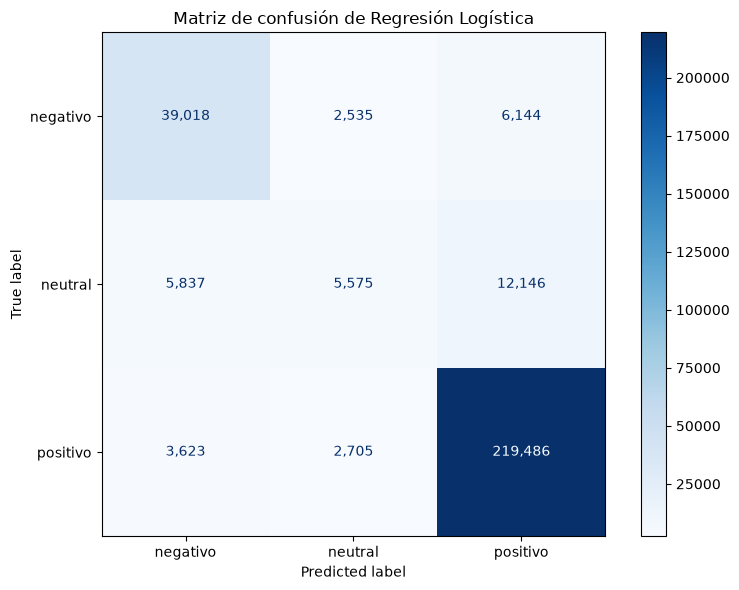

In [19]:
# Matriz confusión absoluta
from matplotlib import pyplot as plt


orden_clases = [
    "negativo",
    "neutral",
    "positivo"
]

figura, eje = plt.subplots(
    figsize=(8, 6)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_rl,
    labels=orden_clases,
    cmap="Blues",
    values_format=",",
    ax=eje
)

eje.set_title(
    "Matriz de confusión de Regresión Logística"
)

figura.tight_layout()

figura.savefig(
    RUTA_REGRESION_LOGISTICA
    / "matriz_confusion_regresion_logistica.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(figura)


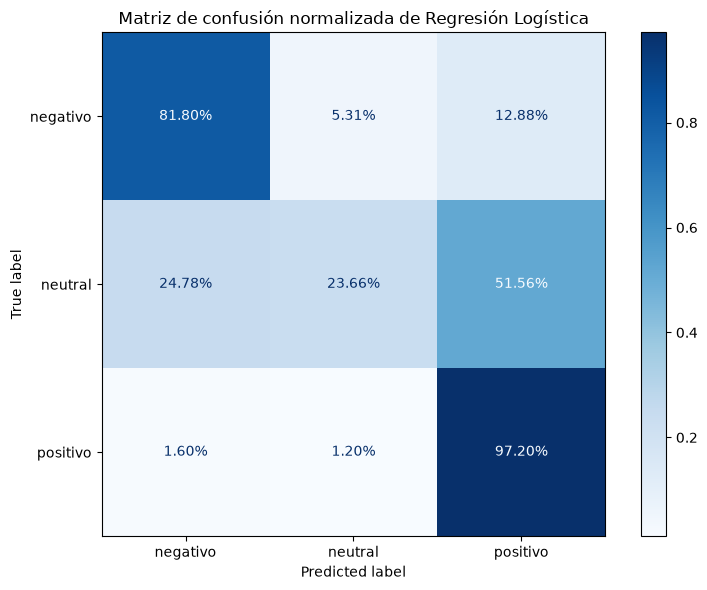

In [20]:
# Matriz confusión normalizada

figura_normalizada, eje_normalizado = (
    plt.subplots(
        figsize=(8, 6)
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_rl,
    labels=orden_clases,
    normalize="true",
    cmap="Blues",
    values_format=".2%",
    ax=eje_normalizado
)

eje_normalizado.set_title(
    "Matriz de confusión normalizada "
    "de Regresión Logística"
)

figura_normalizada.tight_layout()

figura_normalizada.savefig(
    RUTA_REGRESION_LOGISTICA
    / "matriz_confusion_normalizada_regresion_logistica.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(figura_normalizada)

In [21]:
# Predicciones con los textos

datos_test_rl = datos_test.copy()

datos_test_rl["sentiment_predicted"] = (
    predicciones_rl
)

datos_test_rl["prediccion_correcta"] = (
    datos_test_rl["sentiment"]
    == datos_test_rl["sentiment_predicted"]
)

datos_test_rl.to_parquet(
    RUTA_REGRESION_LOGISTICA
    / "resultados_predicciones_regresion_logistica.parquet",
    index=False
)

print(
    "Predicciones asociadas a los textos guardadas."
)

Predicciones asociadas a los textos guardadas.


In [22]:
# Comprobación de archivos

archivos_guardados = sorted(
    RUTA_REGRESION_LOGISTICA.iterdir()
)

print("\nARCHIVOS GUARDADOS")
print("------------------")

for archivo in archivos_guardados:
    tamano_mb = (
        archivo.stat().st_size
        / 1024**2
    )

    print(
        f"{archivo.name}: "
        f"{tamano_mb:.2f} MB"
    )


ARCHIVOS GUARDADOS
------------------
informe_clasificacion_regresion_logistica.csv: 0.00 MB
matriz_confusion_normalizada_regresion_logistica.png: 0.11 MB
matriz_confusion_regresion_logistica.png: 0.11 MB
metricas_regresion_logistica.json: 0.00 MB
modelo_regresion_logistica.joblib: 0.57 MB
predicciones_regresion_logistica.npy: 0.57 MB
resultados_predicciones_regresion_logistica.parquet: 38.02 MB
resultados_regresion_logistica.csv: 0.00 MB
